In [4]:
import pandas as pd
import numpy as np
import torch

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = pd.read_csv("train.csv")

xdata = data.drop(columns=["project_id", "hours_spent"])
ydata = np.log1p(data["hours_spent"])

X_train, X_val, y_train, y_val = train_test_split(
    xdata,
    ydata,
    test_size=0.2,
    random_state=67
)

cat_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

num_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

#replace missing values
for col in num_features:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_val[col] = X_val[col].fillna(median)

for col in cat_features:
    X_train[col] = X_train[col].fillna("Unknown")
    X_val[col] = X_val[col].fillna("Unknown")


X_train = pd.get_dummies(
    X_train,
    columns=cat_features
)

X_val = pd.get_dummies(
    X_val,
    columns=cat_features
)

X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

scaler = StandardScaler()

X_train[num_features] = scaler.fit_transform(
    X_train[num_features]
)

X_val[num_features] = scaler.transform(
    X_val[num_features]
)

X_train = X_train.astype(np.float32)
X_val = X_val.astype(np.float32)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Number of features:", X_train.shape[1])


Training shape: (3600, 152)
Validation shape: (900, 152)
Number of features: 152


/var/folders/md/mlh0thj112j47wjyx89ztj8r0000gn/T/ipykernel_76899/3305841661.py:20: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X_train.select_dtypes(


In [5]:
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(67)

device = torch.device("cpu") #no gpu

xTrainTensor = torch.tensor(X_train.values, dtype=torch.float32)
xValTensor = torch.tensor(X_val.values, dtype=torch.float32)

loader = DataLoader(TensorDataset(xTrainTensor), batch_size=62, shuffle=True)

class Autoencoder(nn.Module):
    def __init__(self, input_dim, embedding_dim=8):
        super().__init__()
        self.encoder = nn.Sequential( #magic
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, embedding_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(embedding_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )
    def forward(self, a):
        embedding = self.encoder(a)
        reconstruction = self.decoder(embedding)
        return reconstruction

model = Autoencoder(input_dim=X_train.shape[1], embedding_dim=8).to(device)

criterion = nn.MSELoss() #loss function

optimizer = torch.optim.Adam( #magic
    model.parameters(),
    lr=0.001
)

epochs = 100

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for (batch,) in loader:

        batch = batch.to(device)

        reconstructed = model(batch)

        loss = criterion(reconstructed, batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(loader)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{epochs} "
            f"Loss: {average_loss:.6f}"
        )



Epoch 10/100 Loss: 0.182451
Epoch 20/100 Loss: 0.148578
Epoch 30/100 Loss: 0.129355
Epoch 40/100 Loss: 0.116862
Epoch 50/100 Loss: 0.107302
Epoch 60/100 Loss: 0.108992
Epoch 70/100 Loss: 0.099092
Epoch 80/100 Loss: 0.096679
Epoch 90/100 Loss: 0.092146
Epoch 100/100 Loss: 0.089321


In [6]:
print("NaN:", X_train.isna().sum().sum())
print("Infinite:", np.isinf(X_train.values).sum())
print("Shape:", X_train.shape)
print("Device:", device)

NaN: 0
Infinite: 0
Shape: (3600, 152)
Device: cpu


In [7]:
model.eval()

with torch.no_grad():
    train_embeddings = model.encoder(
        xTrainTensor.to(device)
    ).cpu().numpy()

    val_embeddings = model.encoder(
        xValTensor.to(device)
    ).cpu().numpy()

print("Training embeddings:", train_embeddings.shape)
print("Validation embeddings:", val_embeddings.shape)

print("\nFirst project embedding:")
print(train_embeddings[0])

Training embeddings: (3600, 8)
Validation embeddings: (900, 8)

First project embedding:
[ 0.5955124  -2.1490936   0.30425528 -2.0009878  -0.93071204 -0.6052119
  7.049806   -2.5137157 ]


GBDT

In [12]:

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.metrics import root_mean_squared_log_error

seeds = [1, 7, 21, 42, 67, 100, 123, 202, 321, 42 + 1000]

actual_hours = np.expm1(y_val)

results = []

for seed in seeds:

    print(f"\nTraining with seed {seed}...")

    model = CatBoostRegressor(
        iterations=3000,
        depth=6,
        learning_rate=0.03,
        loss_function="RMSE",
        random_seed=seed,
        verbose=False,
        early_stopping_rounds=150
    )

    model.fit(
        train_embeddings,
        y_train,
        eval_set=(val_embeddings, y_val),
        use_best_model=True
    )

    predictions_log = model.predict(val_embeddings)

    predictions = np.expm1(
        np.maximum(predictions_log, 0)
    )

    score = root_mean_squared_log_error(
        actual_hours,
        predictions
    )

    results.append({
        "seed": seed,
        "score": score,
        "best_iteration": model.best_iteration_
    })

    print(
        f"Seed: {seed} | "
        f"RMSLE: {score:.6f} | "
        f"Best iteration: {model.best_iteration_}"
    )


results = pd.DataFrame(results)

print("\n" + "=" * 55)
print("MULTI-SEED RESULTS")
print("=" * 55)

print(results.to_string(index=False))

print("\nSUMMARY")
print(f"Mean RMSLE: {results['score'].mean():.6f}")
print(f"Std RMSLE:  {results['score'].std():.6f}")
print(f"Best RMSLE: {results['score'].min():.6f}")
print(f"Worst RMSLE: {results['score'].max():.6f}")

results.to_csv("embedding_seed_results.csv", index=False)



Training with seed 1...
Seed: 1 | RMSLE: 0.609476 | Best iteration: 1446

Training with seed 7...
Seed: 7 | RMSLE: 0.610589 | Best iteration: 1491

Training with seed 21...
Seed: 21 | RMSLE: 0.608606 | Best iteration: 1491

Training with seed 42...
Seed: 42 | RMSLE: 0.614667 | Best iteration: 1118

Training with seed 67...
Seed: 67 | RMSLE: 0.610463 | Best iteration: 1405

Training with seed 100...
Seed: 100 | RMSLE: 0.610646 | Best iteration: 1433

Training with seed 123...
Seed: 123 | RMSLE: 0.607590 | Best iteration: 1269

Training with seed 202...
Seed: 202 | RMSLE: 0.609062 | Best iteration: 990

Training with seed 321...
Seed: 321 | RMSLE: 0.608613 | Best iteration: 1084

Training with seed 1042...
Seed: 1042 | RMSLE: 0.612443 | Best iteration: 1171

MULTI-SEED RESULTS
 seed    score  best_iteration
    1 0.609476            1446
    7 0.610589            1491
   21 0.608606            1491
   42 0.614667            1118
   67 0.610463            1405
  100 0.610646            1

Visualise

Projects: 4500
Embedding dimensions: 8
Running UMAP...


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP complete!


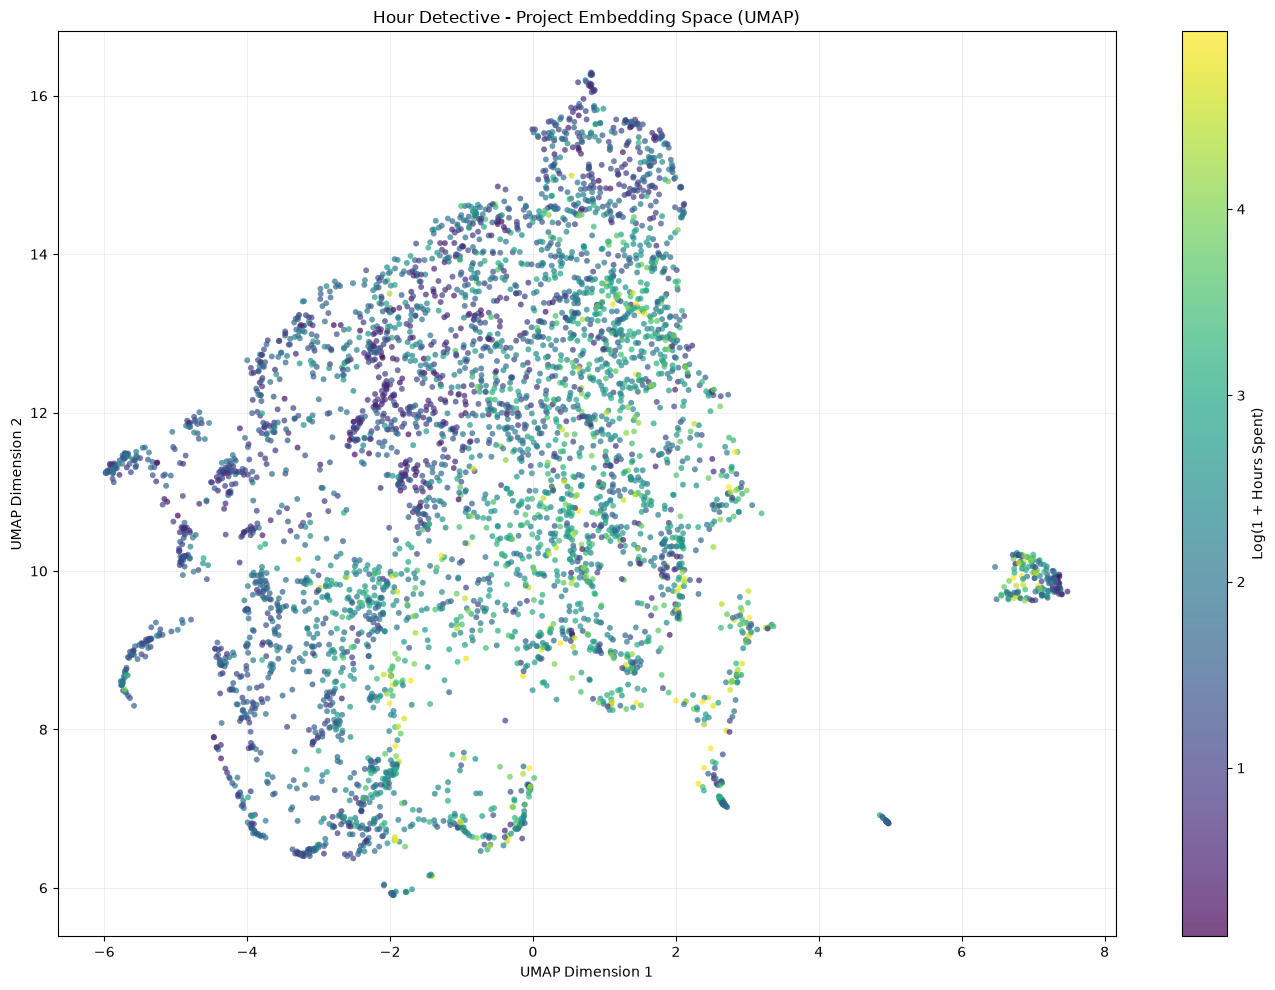

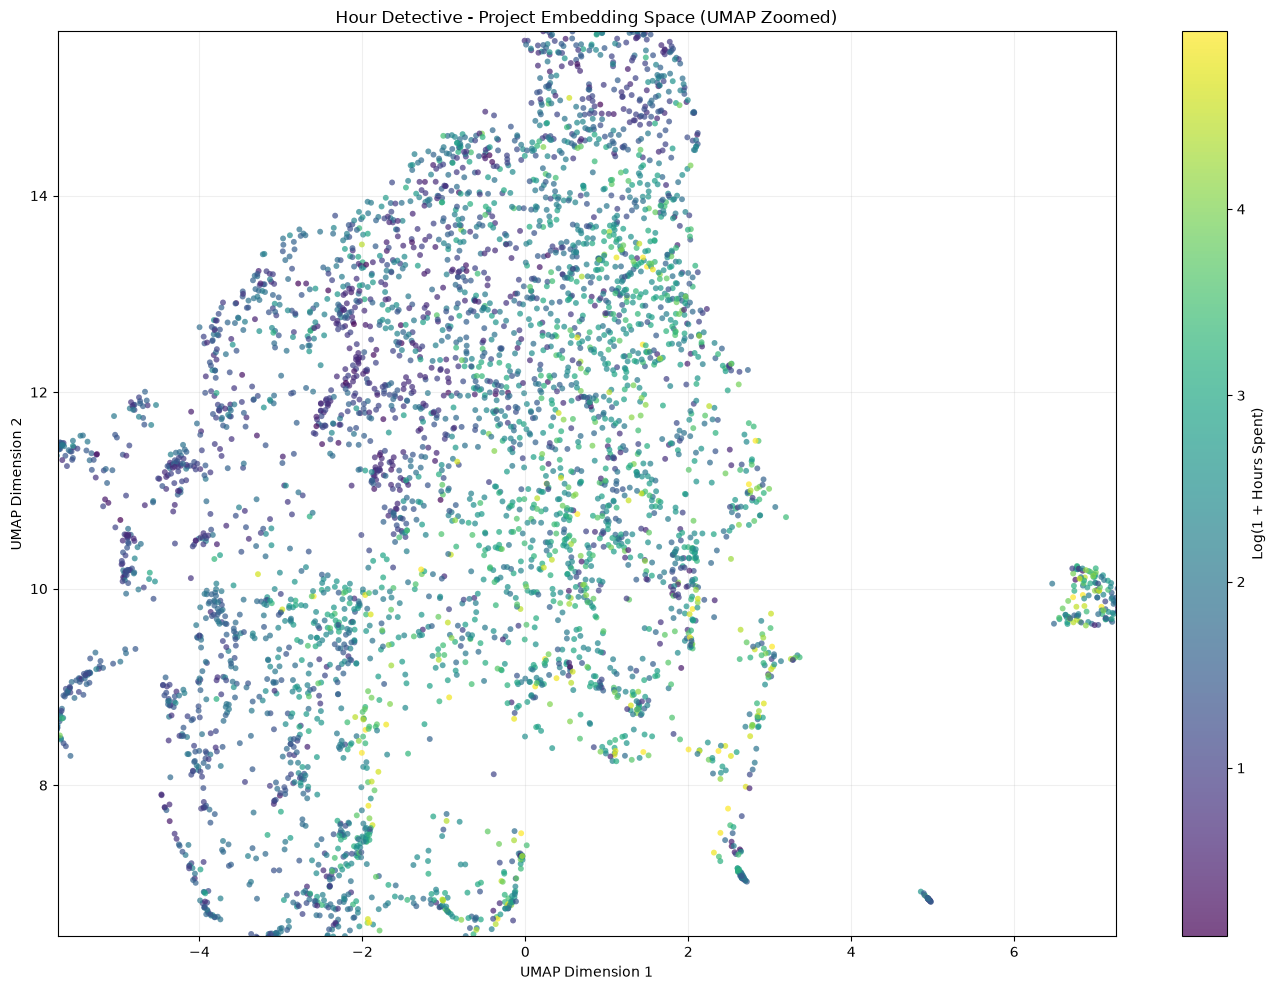

In [8]:

import numpy as np
import umap
import matplotlib.pyplot as plt

# Combine existing embeddings
all_embeddings = np.vstack([
    train_embeddings,
    val_embeddings
])

# Recover actual hours from log-transformed targets
all_hours = np.concatenate([
    np.expm1(y_train),
    np.expm1(y_val)
])

hours = np.log1p(all_hours)

print("Projects:", len(all_embeddings))
print("Embedding dimensions:", all_embeddings.shape[1])

# Generate UMAP coordinates
print("Running UMAP...")

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=30,
    min_dist=0.1,
    metric="euclidean",
    random_state=67
)

umap_space = reducer.fit_transform(all_embeddings)

print("UMAP complete!")


# Full visualisation
fig, ax = plt.subplots(figsize=(14, 10))

scatter = ax.scatter(
    umap_space[:, 0],
    umap_space[:, 1],
    c=hours,
    cmap="viridis",
    s=18,
    alpha=0.7,
    edgecolors="none"
)

fig.colorbar(
    scatter,
    ax=ax,
    label="Log(1 + Hours Spent)"
)

ax.set_title("Hour Detective - Project Embedding Space (UMAP)")
ax.set_xlabel("UMAP Dimension 1")
ax.set_ylabel("UMAP Dimension 2")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("umap_full.png", dpi=250)
plt.show()


# Zoomed visualisation
x_min, x_max = np.percentile(
    umap_space[:, 0], [1, 99]
)

y_min, y_max = np.percentile(
    umap_space[:, 1], [1, 99]
)

fig, ax = plt.subplots(figsize=(14, 10))

scatter = ax.scatter(
    umap_space[:, 0],
    umap_space[:, 1],
    c=hours,
    cmap="viridis",
    s=18,
    alpha=0.7,
    edgecolors="none"
)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

fig.colorbar(
    scatter,
    ax=ax,
    label="Log(1 + Hours Spent)"
)

ax.set_title("Hour Detective - Project Embedding Space (UMAP Zoomed)")
ax.set_xlabel("UMAP Dimension 1")
ax.set_ylabel("UMAP Dimension 2")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("umap_zoomed.png", dpi=250)
plt.show()


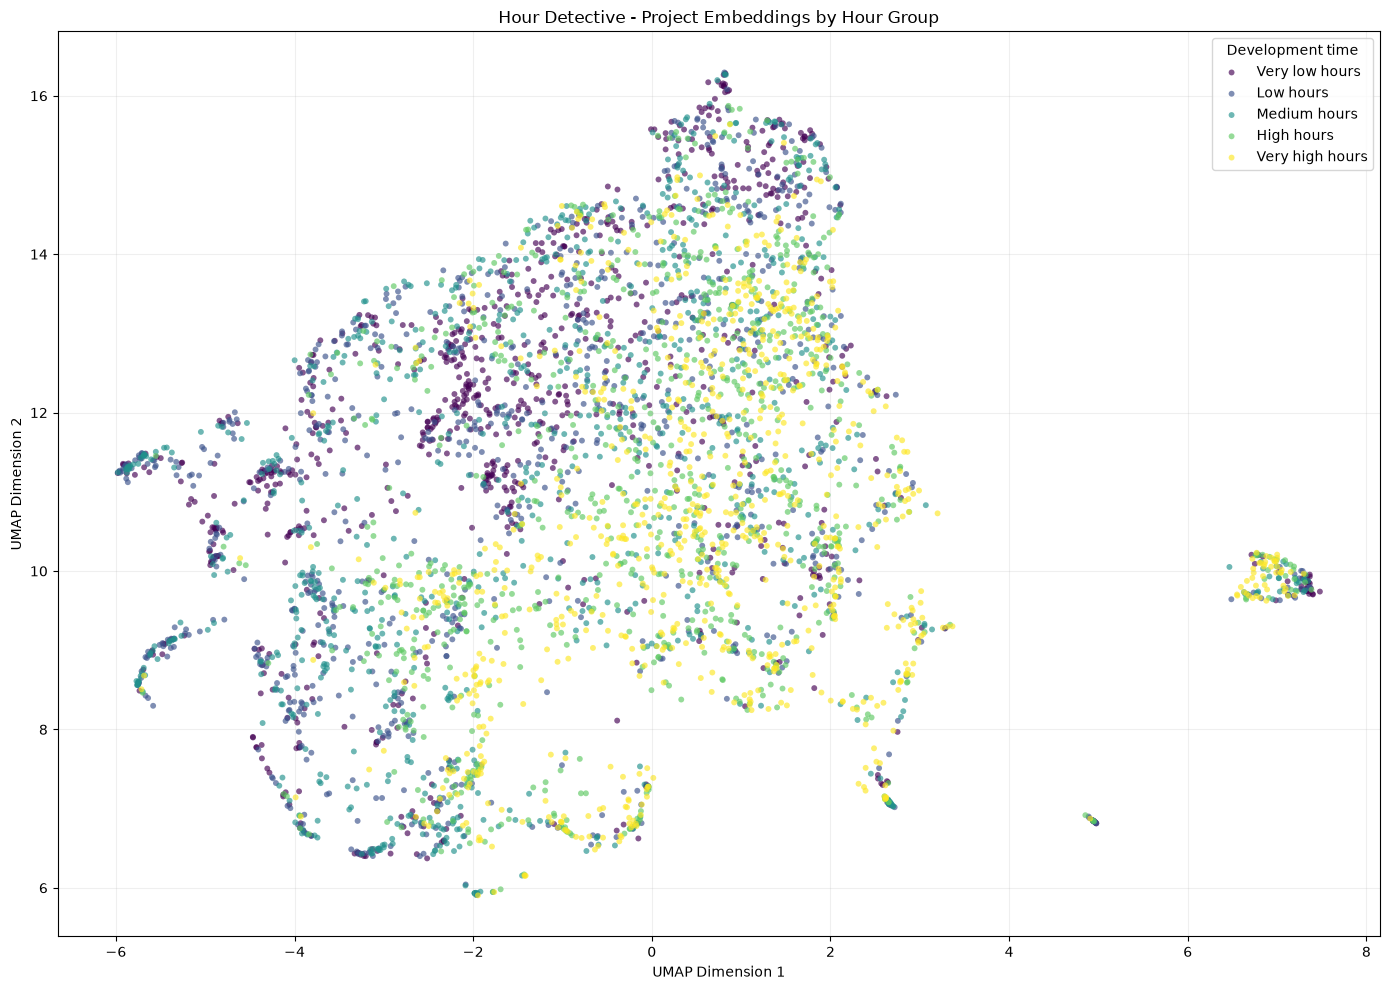

In [9]:
all_hours = np.concatenate([
    np.expm1(y_train),
    np.expm1(y_val)
])

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Divide projects into five equal-sized groups
hour_groups = pd.qcut(
    all_hours,
    q=5,
    labels=[
        "Very low hours",
        "Low hours",
        "Medium hours",
        "High hours",
        "Very high hours"
    ]
)

fig, ax = plt.subplots(figsize=(14, 10))

colors = [
    "#440154",
    "#3B528B",
    "#21918C",
    "#5EC962",
    "#FDE725"
]

for i, label in enumerate(hour_groups.categories):
    mask = np.asarray(hour_groups == label)

    ax.scatter(
        umap_space[mask, 0],
        umap_space[mask, 1],
        color=colors[i],
        label=label,
        s=18,
        alpha=0.65,
        edgecolors="none"
    )

ax.set_title("Hour Detective - Project Embeddings by Hour Group")
ax.set_xlabel("UMAP Dimension 1")
ax.set_ylabel("UMAP Dimension 2")

ax.legend(title="Development time")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("umap_hour_groups.png", dpi=250)
plt.show()
